# Ponto 5 · Políticas de retenção do UnimNeuron-Safe

**Pergunta experimental.** Quando o limite de regras já foi atingido, como muda a capacidade de adaptação e reutilização de regras se o UnimNeuron escolher a regra a remover por suporte acumulado, por uso recente ou por antiguidade?

Comparamos as três políticas no AGRAWAL gradual já estudado e num stream recorrente. O primeiro permite observar a adaptação a B. O segundo permite observar o que acontece quando o conceito A regressa.

## 1. Políticas e desenho experimental

| Política | Regra removida quando é criada uma candidata acima do limite |
|---|---|
| **Suporte** | O modelo original avalia todas as regras, incluindo a candidata. Remove a de menor suporte estrutural acumulado. Em caso de empate, remove a primeira na ordem do modelo. |
| **LRU adaptada** | A candidata entra e sai a residente que há mais tempo teve a maior ativação positiva numa previsão. Uma residente que nunca foi dominante tem prioridade para sair. Em caso de empate, sai a residente mais antiga. |
| **FIFO** | A candidata entra e sai a residente criada há mais tempo, independentemente do seu uso. |

A lógica de criação, adaptação, previsão e fusão é partilhada. Só se especializa a escolha da regra a remover. A comparação com a política original mede o efeito da política completa, incluindo a admissão da candidata. A comparação LRU–FIFO mantém a mesma regra de admissão e permite observar o efeito do critério de remoção.

| Cenário | Dados | Configurações |
|---|---|---|
| **A→B gradual** | 20 000 observações. Função AGRAWAL 0 passa para a função 2, com centro da transição na observação 2 500 e largura 1 000. Reutiliza a experiência anterior, incluindo a escala e as seeds. | Limite de 5. |
| **A–B–A abrupto** | 15 000 observações em três fases puras de 5 000. A1 e A2 usam a mesma função 0 com amostras novas. B usa a função 2. Para cada seed s, as fases usam seeds 3s, 3s+1 e 3s+2. | Limite de 5 com seeds 42, 43 e 44. Verificação de sensibilidade com limites de 10 e 20 na seed 42. |

Dentro de cada cenário, seed e orçamento, as três políticas recebem exatamente a mesma sequência. Cada observação é avaliada antes de atualizar o modelo. A normalização min–max usa o stream completo para manter o protocolo dos pontos anteriores. É uma comparação experimental com pré-processamento partilhado e acesso antecipado aos extremos das variáveis.

In [1]:
import json
from pathlib import Path
from statistics import mean
from IPython.display import Image, Markdown, display

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "ENF_UnimNeuron_Safe.py").is_file())
results = root / "results" / "6_retention"
report = json.loads((results / "summary.json").read_text(encoding="utf-8"))
ab = next(case for case in report["cases"] if case["scenario"] == "ab")
aba = [case for case in report["cases"] if case["scenario"] == "aba"]
primary = [case for case in aba if case["budget"] == 5]
names = dict(support="Suporte", lru="LRU adaptada", fifo="FIFO")

def number(value, decimals=3):
    return f"{value:.{decimals}f}".replace(".", ",")

def percent(value):
    return number(100 * value, 1) + "%"

def delay(recovery):
    value = recovery["delay"]
    return str(value) if value is not None else "Limiar não atingido"

def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 2. Métricas

- **Macro-F1 prequential** é a média do F1 das duas classes, calculada com as previsões feitas antes de cada atualização. Cada classe tem o mesmo peso, mesmo que uma seja menos frequente. Apresentamos o macro-F1 global e por fase.
- **Substituição de uma residente** conta uma remoção provocada pelo limite em que sai uma regra que já existia. Quando sai a própria candidata, contamos uma rejeição imediata. As fusões têm eventos próprios.
- **Recuperação operacional** é o primeiro momento em que dois blocos consecutivos de 250 observações atingem 90% do macro-F1 dos últimos 1 000 exemplos de A inicial, para a própria política. O atraso conta desde o primeiro exemplo da fase avaliada até ao fim do segundo bloco. No gradual, começa na observação 3 001, no fim do intervalo de transição usado no ponto anterior. Um atraso de 500 é o mínimo detetável. A tabela inclui o limiar porque ele pode ser mais baixo para uma política com pior desempenho inicial. Repetimos também a medição com um limiar comum, igual ao maior dos três limiares no mesmo cenário, seed e orçamento.
- **Reutilização em A2** acompanha a coorte de IDs ativos no fim de A1. Medimos quantos sobrevivem até ao regresso, quantos voltam a ser dominantes e que fração da ativação total lhes cabe em A2. Um ID pode continuar ativo e ter sido adaptado durante B. A ativação mostra a utilização da regra, enquanto o macro-F1 mede a qualidade da classificação.

## 3. Mudança gradual A→B

In [2]:
assert report["support_matches_ab_baseline"]
table(["Política", "Global", "Antes", "Transição", "Depois", "Rejeições imediatas",
       "Substituições", "Limiar", "Recup. individual", "Recup. comum"],
      [(names[policy], number(run["macro_f1"]), number(run["phase_f1"]["A"]),
        number(run["phase_f1"]["Transição"]), number(run["phase_f1"]["B"]),
        run["immediate_evictions"], run["replacements"], number(run["recovery"]["B"]["threshold"]),
        delay(run["recovery"]["B"]), delay(run["common_recovery"]["B"]))
       for policy, run in ab["runs"].items()])
display(Markdown("Limiar comum após a transição: **" +
                 number(ab["runs"]["support"]["common_recovery"]["B"]["threshold"]) + "**."))

| Política | Global | Antes | Transição | Depois | Rejeições imediatas | Substituições | Limiar | Recup. individual | Recup. comum |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Suporte | 0,438 | 0,411 | 0,381 | 0,436 | 19035 | 4 | 0,364 | 2000 | 2250 |
| LRU adaptada | 0,490 | 0,424 | 0,482 | 0,485 | 0 | 1538 | 0,363 | 1000 | 1000 |
| FIFO | 0,509 | 0,479 | 0,485 | 0,504 | 0 | 4764 | 0,422 | 500 | 500 |

Limiar comum após a transição: **0,422**.

FIFO obteve o maior macro-F1 global (0,509), seguida pela LRU adaptada (0,490) e pelo suporte (0,438). A ordem mantém-se na fase depois da transição. Com o limiar comum de cerca de 0,422, FIFO precisou de 500 observações, LRU de 1 000 e suporte de 2 250. No orçamento de cinco, o suporte recusou imediatamente 19 035 candidatas e substituiu apenas quatro residentes. LRU substituiu 1 538 residentes e FIFO 4 764. A política de admissão ajuda a explicar a diferença de renovação entre suporte e as duas alternativas.

## 4. Regresso ao conceito A com cinco regras

As linhas mostram os três ensaios emparelhados. As colunas de recuperação apresentam o atraso em observações. O F1 dos primeiros 1 000 exemplos de A2 dá uma comparação direta do desempenho inicial após o regresso.

In [3]:
table(["Seed", "Política", "Global", "A1", "B", "A2", "A2 inicial",
       "Limiar", "Recup. B", "Recup. A2"],
      [(case["seed"], names[policy], *(number(run["phase_f1"][p]) if p != "global"
                                     else number(run["macro_f1"]) for p in ("global", "A1", "B", "A2")),
        number(run["memory"]["first_1000_f1"]), number(run["recovery"]["A2"]["threshold"]),
        delay(run["recovery"]["B"]), delay(run["recovery"]["A2"]))
       for case in primary for policy, run in case["runs"].items()])

table(["Política", "Macro-F1 B médio", "Macro-F1 A2 médio", "Macro-F1 A2 inicial médio"],
      [(names[policy], number(mean(case["runs"][policy]["phase_f1"]["B"] for case in primary)),
        number(mean(case["runs"][policy]["phase_f1"]["A2"] for case in primary)),
        number(mean(case["runs"][policy]["memory"]["first_1000_f1"] for case in primary)))
       for policy in names])

| Seed | Política | Global | A1 | B | A2 | A2 inicial | Limiar | Recup. B | Recup. A2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 42 | Suporte | 0,422 | 0,403 | 0,415 | 0,405 | 0,403 | 0,365 | 750 | 500 |
| 42 | LRU adaptada | 0,465 | 0,415 | 0,472 | 0,412 | 0,412 | 0,370 | 500 | 500 |
| 42 | FIFO | 0,505 | 0,459 | 0,495 | 0,475 | 0,492 | 0,404 | 500 | 500 |
| 43 | Suporte | 0,430 | 0,401 | 0,434 | 0,406 | 0,404 | 0,358 | 750 | 500 |
| 43 | LRU adaptada | 0,466 | 0,418 | 0,476 | 0,415 | 0,418 | 0,360 | 500 | 500 |
| 43 | FIFO | 0,501 | 0,469 | 0,505 | 0,454 | 0,429 | 0,439 | 500 | 1250 |
| 44 | Suporte | 0,433 | 0,404 | 0,442 | 0,400 | 0,406 | 0,364 | 1250 | 500 |
| 44 | LRU adaptada | 0,460 | 0,416 | 0,475 | 0,410 | 0,418 | 0,376 | 1750 | 500 |
| 44 | FIFO | 0,501 | 0,452 | 0,504 | 0,472 | 0,471 | 0,390 | 500 | 500 |

| Política | Macro-F1 B médio | Macro-F1 A2 médio | Macro-F1 A2 inicial médio |
| --- | --- | --- | --- |
| Suporte | 0,430 | 0,403 | 0,404 |
| LRU adaptada | 0,474 | 0,412 | 0,416 |
| FIFO | 0,501 | 0,467 | 0,464 |

In [4]:
table(["Seed", "Política", "Coorte A1", "Sobrevivem a B", "IDs dominantes em A2",
       "Domínio em A2", "Ativação em A2", "Rejeições", "Substituições"],
      [(case["seed"], names[policy], len(run["memory"]["cohort_ids"]),
        len(run["memory"]["survived_ids"]), len(run["memory"]["reused_ids"]),
        percent(run["memory"]["dominance_share"]), percent(run["memory"]["activation_share"]),
        run["immediate_evictions"], run["replacements"])
       for case in primary for policy, run in case["runs"].items()])

| Seed | Política | Coorte A1 | Sobrevivem a B | IDs dominantes em A2 | Domínio em A2 | Ativação em A2 | Rejeições | Substituições |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 42 | Suporte | 5 | 5 | 1 | 100,0% | 100,0% | 14686 | 18 |
| 42 | LRU adaptada | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 1067 |
| 42 | FIFO | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 3356 |
| 43 | Suporte | 5 | 5 | 1 | 100,0% | 100,0% | 14621 | 13 |
| 43 | LRU adaptada | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 1163 |
| 43 | FIFO | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 3481 |
| 44 | Suporte | 5 | 5 | 5 | 100,0% | 100,0% | 14722 | 22 |
| 44 | LRU adaptada | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 1138 |
| 44 | FIFO | 5 | 0 | 0 | 0,0% | 0,0% | 0 | 3381 |

In [5]:
table(["Seed", "Limiar comum", "Suporte (B / A2)", "LRU (B / A2)", "FIFO (B / A2)"],
      [(case["seed"], number(case["runs"]["support"]["common_recovery"]["A2"]["threshold"]),
        *(" / ".join(delay(case["runs"][policy]["common_recovery"][phase]) for phase in ("B", "A2"))
          for policy in names)) for case in primary])

| Seed | Limiar comum | Suporte (B / A2) | LRU (B / A2) | FIFO (B / A2) |
| --- | --- | --- | --- | --- |
| 42 | 0,404 | 1000 / 2000 | 1000 / 1000 | 500 / 500 |
| 43 | 0,439 | Limiar não atingido / Limiar não atingido | 500 / Limiar não atingido | 500 / 1250 |
| 44 | 0,390 | 1250 / 500 | 1750 / 500 | 500 / 500 |

Com cinco regras, **FIFO obteve o maior macro-F1 em A2 em todas as três seeds**, com média de 0,467, seguida de LRU (0,412) e suporte (0,403). FIFO também teve o maior macro-F1 nos primeiros 1 000 exemplos de A2 em cada seed. Com o limiar comum, FIFO foi a mais rápida ou empatou no regresso a A. Na seed 43, foi a única a atingir o limiar e precisou de 1 250 observações. Com o limiar individual, suporte e LRU chegam ao mínimo detetável de 500 em todas as seeds. Esse resultado deve ser lido com os limiares inferiores de ambas.

O **suporte preservou os cinco IDs** do fim de A1 em cada seed e essa coorte concentrou toda a ativação no regresso. LRU e FIFO terminaram B sem nenhum desses IDs. A sobrevivência das regras iniciais comprova a retenção estrutural. As métricas de A2 mostram que, nestes streams, a política com maior retenção estrutural ficou atrás das duas alternativas no desempenho preditivo. Como as regras sobreviventes continuam a ser atualizadas em B, a sobrevivência do ID não demonstra que o conteúdo aprendido em A1 se manteve intacto.

## 5. Sensibilidade ao limite de regras

Repetimos o mesmo stream recorrente da seed 42 com três orçamentos. A mudança de orçamento é avaliada dentro de cada política.

| Orçamento | Política | Macro-F1 B | Macro-F1 A2 | Sobrevivem a B | Ativação em A2 | Rejeições | Substituições |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | Suporte | 0,415 | 0,405 | 5 | 100,0% | 14686 | 18 |
| 5 | LRU adaptada | 0,472 | 0,412 | 0 | 0,0% | 0 | 1067 |
| 5 | FIFO | 0,495 | 0,475 | 0 | 0,0% | 0 | 3356 |
| 10 | Suporte | 0,411 | 0,405 | 10 | 88,6% | 13376 | 8 |
| 10 | LRU adaptada | 0,428 | 0,405 | 1 | 11,0% | 0 | 434 |
| 10 | FIFO | 0,458 | 0,411 | 0 | 0,0% | 0 | 772 |
| 20 | Suporte | 0,398 | 0,405 | 19 | 94,7% | 9675 | 17 |
| 20 | LRU adaptada | 0,404 | 0,405 | 4 | 13,6% | 0 | 187 |
| 20 | FIFO | 0,418 | 0,405 | 0 | 0,0% | 0 | 259 |

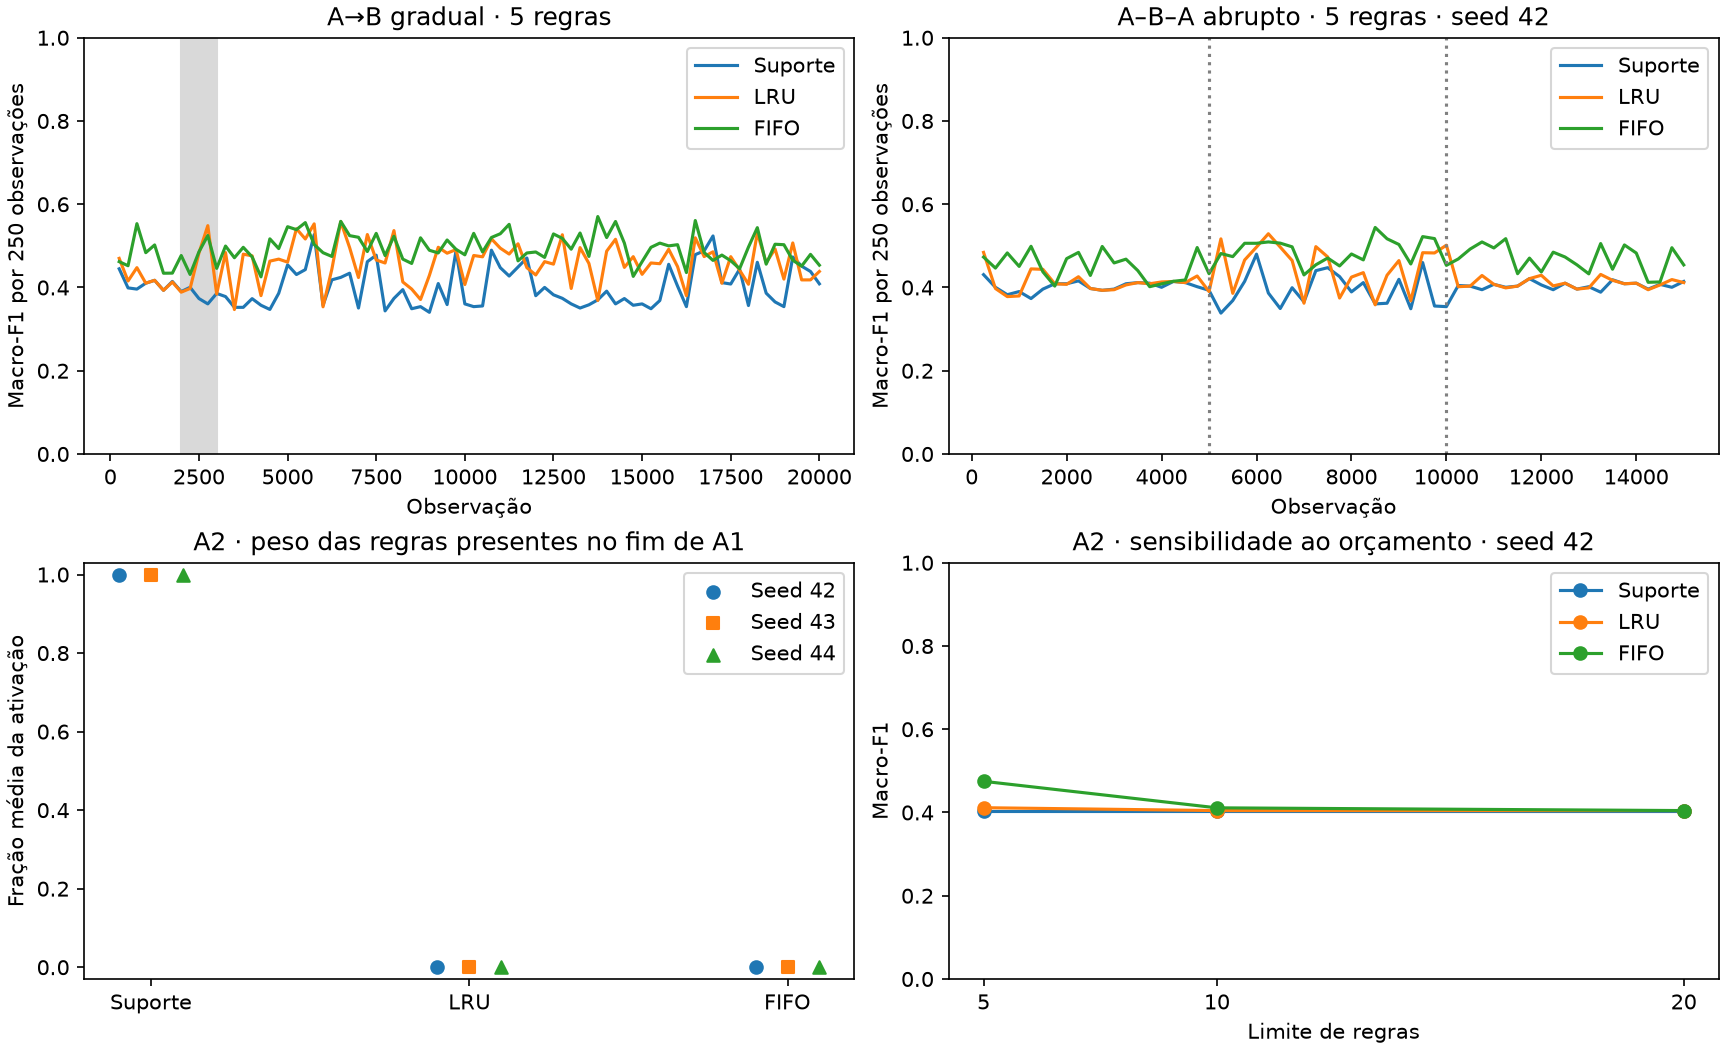

In [6]:
table(["Orçamento", "Política", "Macro-F1 B", "Macro-F1 A2", "Sobrevivem a B",
       "Ativação em A2", "Rejeições", "Substituições"],
      [(case["budget"], names[policy], number(run["phase_f1"]["B"]),
        number(run["phase_f1"]["A2"]), len(run["memory"]["survived_ids"]),
        percent(run["memory"]["activation_share"]), run["immediate_evictions"], run["replacements"])
       for case in aba if case["seed"] == 42 for policy, run in case["runs"].items()])

display(Image(filename=str(results / "retention.png")))

Nos gráficos de cima, cada ponto resume um bloco de 250 observações. A zona sombreada marca a transição gradual e as linhas verticais marcam as mudanças abruptas. Em baixo, comparamos a utilização da coorte inicial em A2 entre seeds e o macro-F1 em A2 entre orçamentos.

Na seed 42, o macro-F1 de FIFO em A2 passou de 0,475 com cinco regras para 0,411 com dez e 0,405 com vinte. Com vinte regras, as três políticas ficaram com o mesmo macro-F1 em A2. A LRU preservou zero, uma e quatro regras da coorte de A1, respetivamente. O aumento do orçamento permitiu à LRU manter mais IDs iniciais neste ensaio, mas não produziu uma melhoria correspondente em A2. O suporte reteve muitas mais regras iniciais em todos os limites e o FIFO não conservou nenhuma até ao regresso.

## 6. Conclusões

1. **Adaptação e classificação.** Com cinco regras, FIFO apresentou o melhor macro-F1 no A→B gradual e nas três repetições de A–B–A. Também alcançou primeiro ou empatou na recuperação para um alvo comum.
2. **Memória das regras.** A política original preservou mais regras do primeiro conceito. FIFO teve melhor desempenho em A2 com cinco regras, embora a coorte inicial já tivesse saído. A LRU adaptada reduziu as substituições em relação a FIFO e, com os orçamentos maiores, conseguiu conservar alguns IDs iniciais.
3. **Efeito do orçamento.** A vantagem de FIFO em A2 diminuiu quando o limite aumentou na seed 42. O equilíbrio entre retenção e adaptação depende do orçamento neste teste.

Os resultados caracterizam o AGRAWAL com as funções, seeds e limites testados. A mudança gradual e o estudo dos limites 10 e 20 têm uma seed cada. Os tempos de recuperação dependem do tamanho das janelas e da referência de cada política. A análise por fases e a comparação do F1 inicial em A2 ajudam a interpretar esse indicador.

## 7. Validação e reprodução

A política Suporte reproduziu as **20 000 previsões** e as **20 000 contagens de regras** guardadas no cenário gradual anterior. Em todas as execuções o orçamento foi respeitado após cada atualização e as criações, remoções e absorções reconciliam-se com a contagem final. Os testes em `tests/test_eviction.py` verificam a escolha da vítima em casos controlados, a política sem limite e o orçamento zero.

O ficheiro `summary.json` contém a configuração e as métricas. Os CSV de amostras guardam a classe real, previsão, regras ativas, ID dominante e fração de ativação da coorte de A1. Os CSV de eventos guardam os IDs das candidatas e das regras removidas ou fundidas. Os limites de fase no JSON usam índices de início inclusivo e fim exclusivo, começando em zero.

Para voltar a executar as **18 combinações**, seleciona o Python da `.venv`, muda a opção abaixo para `True` e corre a última célula. Cada linha de progresso representa uma combinação concluída.

In [7]:
import subprocess
import sys

repeat_experiment = False
if repeat_experiment:
    command = [sys.executable, "-u", "-X", "utf8",
               str(root / "experiments" / "retention_comparison.py")]
    with subprocess.Popen(command, cwd=root, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, encoding="utf-8") as process:
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
        except KeyboardInterrupt:
            process.terminate()
            raise
        exit_code = process.wait()
    if exit_code:
        raise subprocess.CalledProcessError(exit_code, command)
